# European Option Pricing Using Black–Scholes

## 1. Import Libraries

We begin by importing the necessary Python libraries for numerical computation, option pricing, and data visualization.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm

## 2. Black–Scholes Model Parameters

We assume a hypothetical stock with the following parameters:

- $S_0$: Initial stock price
- $K$: Strike price
- $T$: Time to maturity (in years)
- $r$: Risk-free interest rate
- $\sigma$: Annualized volatility

For our volatility sensitivity analysis, we consider:

$$
\sigma \in \{0.10,\ 0.20,\ 0.30\}
$$

All other parameters remain constant to isolate the effect of volatility on the European call option price.

In [2]:
# Initial model parameters
S0 = 100       # Initial stock price
K = 100        # Strike price
T = 1.0        # Time to maturity (1 year)
r = 0.05       # Risk-free interest rate (5%)

# Volatility scenarios
sigmas = [0.10, 0.20, 0.30]

print(f"Initial stock price: ${S0}")
print(f"Strike price: ${K}")
print(f"Maturity: {T} year")
print(f"Risk-free rate: {r:.0%}")
print(f"Volatility scenarios: {[f'{s:.0%}' for s in sigmas]}")

Initial stock price: $100
Strike price: $100
Maturity: 1.0 year
Risk-free rate: 5%
Volatility scenarios: ['10%', '20%', '30%']


## 3. Black–Scholes European Call Option

The Black–Scholes model calculates the theoretical price of a European call option:

$$
C(S_0, T) = S_0 N(d_1) - Ke^{-rT}N(d_2)
$$

where

$$
d_1 = \frac{\ln(S_0/K)+(r+\frac{1}{2}\sigma^2)T}{\sigma\sqrt{T}}
$$

$$
d_2 = d_1-\sigma\sqrt{T}
$$

Here, $N(\cdot)$ denotes the cumulative distribution function (CDF) of the standard normal distribution.

We implement this formula as a Python function that accepts volatility $\sigma$ as an input.

In [3]:
def black_scholes_call(S0, K, T, r, sigma):
    # Calculate d1 and d2
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))
    d2 = d1 - sigma * np.sqrt(T)

    # European call option price
    call_price = S0 * norm.cdf(d1) - K * np.exp(-r * T) * norm.cdf(d2)

    return call_price


# Test with sigma = 20%
sigma = 0.20

call_price = black_scholes_call(S0, K, T, r, sigma)

print(f"Volatility: {sigma:.0%}")
print(f"European Call Price: ${call_price:.4f}")

Volatility: 20%
European Call Price: $10.4506


## 4. Impact of Volatility on European Call Option Prices

We investigate how volatility affects the European call option price.

The volatility scenarios are:

$$
\sigma \in \{10\%, 20\%, 30\%\}
$$

We keep $S_0$, $K$, $T$, and $r$ constant while changing only $\sigma$.

Our objective is to observe how the option price responds to increasing volatility.

In [4]:
# Calculate European call prices for different volatilities

results = []

for sigma in sigmas:
    price = black_scholes_call(S0, K, T, r, sigma)

    results.append({
        "Volatility (%)": sigma * 100,
        "Call Price ($)": price
    })

# Convert results into DataFrame
df = pd.DataFrame(results)

print(df.round(4))

   Volatility (%)  Call Price ($)
0            10.0          6.8050
1            20.0         10.4506
2            30.0         14.2313


## 5. Visualization of Volatility Sensitivity

We visualize the relationship between volatility $\sigma$ and the European call option price.

The objective is to observe how increasing volatility affects the option price while keeping all other parameters constant.

We expect the European call option price to increase as volatility increases under the Black–Scholes model.

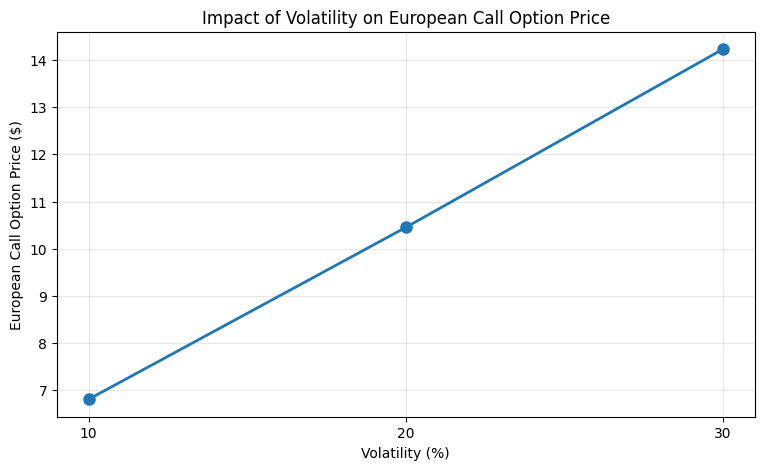

In [5]:
plt.figure(figsize=(9, 5))

plt.plot(
    df["Volatility (%)"],
    df["Call Price ($)"],
    marker="o",
    linewidth=2,
    markersize=8
)

plt.xlabel("Volatility (%)")
plt.ylabel("European Call Option Price ($)")
plt.title("Impact of Volatility on European Call Option Price")

plt.xticks(df["Volatility (%)"])
plt.grid(True, alpha=0.3)

plt.show()

## 6. Changes in European Call Option Prices

We measure how much the European call option price changes when volatility increases.

### Absolute Price Change

$$
\Delta C = C(\sigma_2) - C(\sigma_1)
$$

### Percentage Price Change

$$
\%\Delta C =
\frac{C(\sigma_2)-C(\sigma_1)}{C(\sigma_1)}
\times 100
$$

We compare two scenarios:

- Volatility increases from 10% to 20%.
- Volatility increases from 20% to 30%.

This helps us understand the sensitivity of European call option prices to changes in volatility.

In [6]:
# Calculate absolute and percentage price changes

df["Price Change ($)"] = df["Call Price ($)"].diff()

df["Price Change (%)"] = (
    df["Call Price ($)"].pct_change() * 100
)

print(df.round(4))

   Volatility (%)  Call Price ($)  Price Change ($)  Price Change (%)
0            10.0          6.8050               NaN               NaN
1            20.0         10.4506            3.6456           53.5731
2            30.0         14.2313            3.7807           36.1767


## 7. Vega — Sensitivity of European Call Option to Volatility

Vega measures how sensitive the option price is to changes in volatility.

Mathematically:

$$
\text{Vega} = \frac{\partial C}{\partial \sigma}
$$

Under the Black–Scholes model:

$$
\text{Vega} = S_0 \sqrt{T}\phi(d_1)
$$

where $\phi(d_1)$ is the standard normal probability density function (PDF).

Vega measures the approximate change in option price for a one-unit change in volatility.

For a **1 percentage point increase** in volatility, the approximate price change is:

$$
\Delta C \approx \text{Vega}\times 0.01
$$

We calculate Vega for volatility levels of 10%, 20%, and 30%.

In [7]:
def black_scholes_vega(S0, K, T, r, sigma):
    d1 = (np.log(S0 / K) + (r + 0.5 * sigma**2) * T) / (sigma * np.sqrt(T))

    vega = S0 * np.sqrt(T) * norm.pdf(d1)

    return vega


# Calculate Vega for each volatility scenario
df["Vega"] = [
    black_scholes_vega(S0, K, T, r, sigma)
    for sigma in sigmas
]

# Approximate price change for a 1 percentage point increase
df["Price Change per 1% Vol ($)"] = df["Vega"] * 0.01

print(df[[
    "Volatility (%)",
    "Call Price ($)",
    "Vega",
    "Price Change per 1% Vol ($)"
]].round(4))

   Volatility (%)  Call Price ($)     Vega  Price Change per 1% Vol ($)
0            10.0          6.8050  34.2944                       0.3429
1            20.0         10.4506  37.5240                       0.3752
2            30.0         14.2313  37.9433                       0.3794


## 8. Vega Sensitivity Analysis

We investigate how Vega changes as volatility increases.

Recall that:

$$
\text{Vega} = \frac{\partial C}{\partial \sigma}
$$

A higher Vega indicates that the option price is more sensitive to a small change in volatility.

Our objective is to compare Vega at:

$$
\sigma \in \{10\%, 20\%, 30\%\}
$$

We use the Black–Scholes analytical Vega formula.

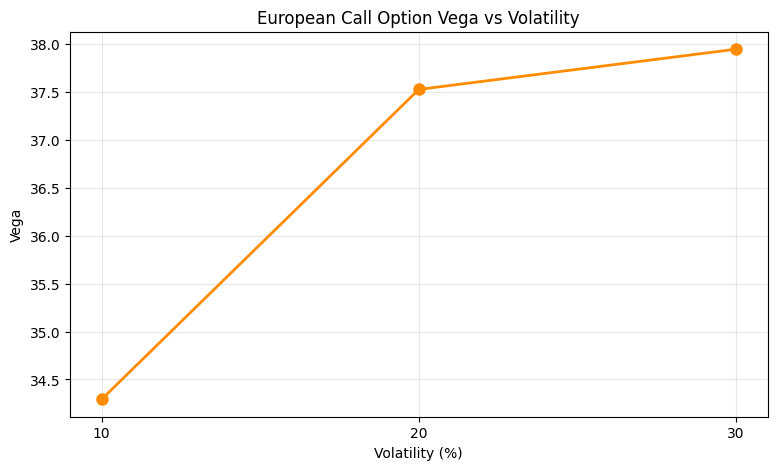

In [8]:
plt.figure(figsize=(9, 5))

plt.plot(
    df["Volatility (%)"],
    df["Vega"],
    marker="o",
    linewidth=2,
    markersize=8,
    color="darkorange"
)

plt.xlabel("Volatility (%)")
plt.ylabel("Vega")
plt.title("European Call Option Vega vs Volatility")

plt.xticks(df["Volatility (%)"])
plt.grid(True, alpha=0.3)

plt.show()

## 9. Stock Price Simulation Using Geometric Brownian Motion

Under the risk-neutral measure, stock prices follow:

$$
dS_t = rS_t\,dt + \sigma S_t\,dW_t
$$

The analytical solution is:

$$
S_t = S_0 \exp\left[\left(r-\frac{1}{2}\sigma^2\right)t+\sigma W_t\right]
$$

For discrete time steps:

$$
S_{t+\Delta t}
=
S_t\exp\left[
\left(r-\frac{1}{2}\sigma^2\right)\Delta t
+\sigma\sqrt{\Delta t}Z
\right]
$$

where:

- $r$: Risk-free interest rate
- $\sigma$: Stock price volatility
- $\Delta t$: Time step
- $Z \sim N(0,1)$: Standard normal random variable

We simulate stock price paths for volatility levels of 10%, 20%, and 30%.

To make the comparison fair, we use the same random shocks for all three volatility scenarios.

In [9]:
# Monte Carlo simulation settings
n_paths = 1000
n_steps = 252
dt = T / n_steps

np.random.seed(42)

# Generate the same random shocks for all volatility scenarios
Z = np.random.normal(size=(n_paths, n_steps))

# Time grid
time = np.linspace(0, T, n_steps + 1)

# Simulate stock prices
stock_paths = {}

for sigma in sigmas:
    paths = np.zeros((n_paths, n_steps + 1))
    paths[:, 0] = S0

    for t in range(1, n_steps + 1):
        paths[:, t] = paths[:, t-1] * np.exp(
            (r - 0.5 * sigma**2) * dt
            + sigma * np.sqrt(dt) * Z[:, t-1]
        )

    stock_paths[sigma] = paths

print("GBM simulation completed.")
print(f"Number of paths: {n_paths}")
print(f"Time steps: {n_steps}")
print(f"Volatility scenarios: {sigmas}")

GBM simulation completed.
Number of paths: 1000
Time steps: 252
Volatility scenarios: [0.1, 0.2, 0.3]


## 10. Visualization of GBM Stock Price Paths

We visualize simulated stock price paths under three volatility scenarios:

$$
\sigma \in \{10\%, 20\%, 30\%\}
$$

The objective is to observe how volatility influences stock price fluctuations.

- **10% volatility:** Smaller fluctuations.
- **20% volatility:** Moderate fluctuations.
- **30% volatility:** Larger fluctuations.

All scenarios use the same initial stock price, risk-free rate, maturity, and random shocks.

We plot the first 20 simulated paths for each volatility scenario.

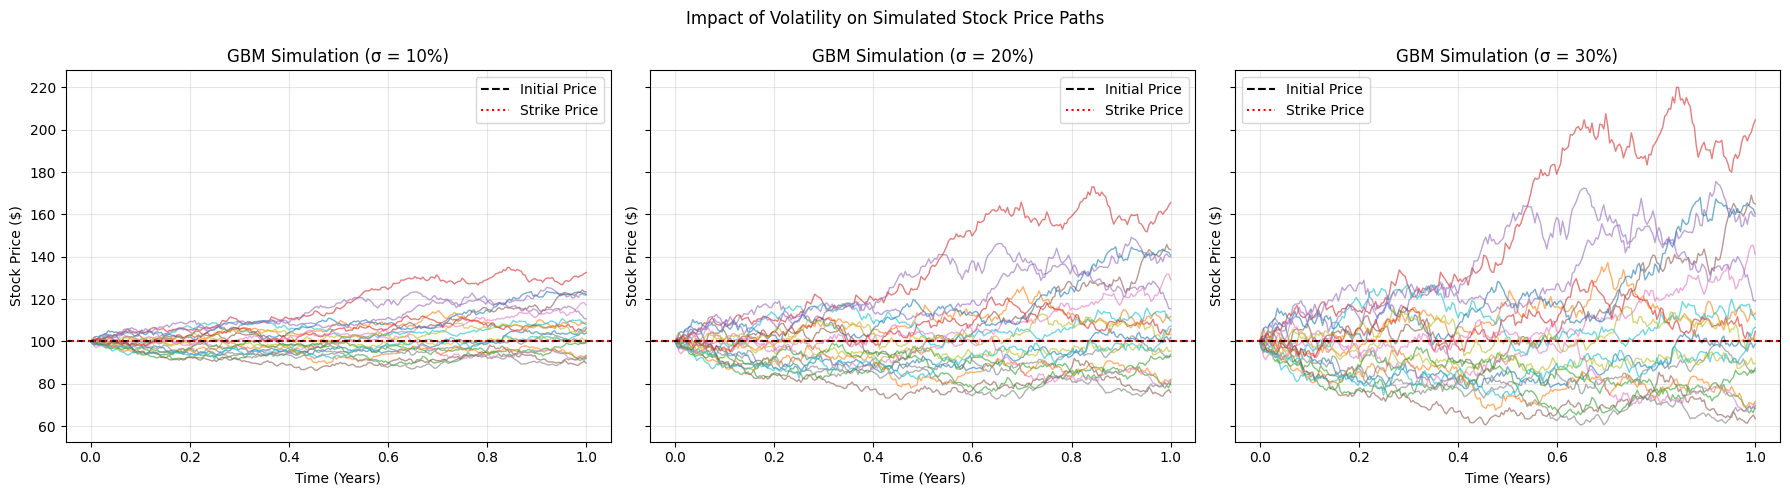

In [10]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)

for ax, sigma in zip(axes, sigmas):

    paths = stock_paths[sigma]

    for i in range(20):
        ax.plot(time, paths[i], alpha=0.6, linewidth=1)

    ax.axhline(S0, color="black", linestyle="--", label="Initial Price")
    ax.axhline(K, color="red", linestyle=":", label="Strike Price")

    ax.set_title(f"GBM Simulation (σ = {sigma:.0%})")
    ax.set_xlabel("Time (Years)")
    ax.set_ylabel("Stock Price ($)")
    ax.grid(alpha=0.3)
    ax.legend()

plt.suptitle("Impact of Volatility on Simulated Stock Price Paths")
plt.tight_layout()
plt.show()

## 11. European Call Option Pricing Using Monte Carlo Simulation

A European call option has the payoff:

$$
C_T = \max(S_T-K,0)
$$

Under the risk-neutral measure, its theoretical price is:

$$
C_0=e^{-rT}\mathbb{E}^{\mathbb{Q}}[\max(S_T-K,0)]
$$

We approximate this expectation using Monte Carlo simulation:

$$
\hat{C}_0=\frac{e^{-rT}}{N}
\sum_{i=1}^{N}\max(S_T^{(i)}-K,0)
$$

where:

- $N$: Number of simulated stock price paths
- $S_T^{(i)}$: Terminal stock price of path $i$
- $K$: Strike price
- $r$: Risk-free interest rate
- $T$: Time to maturity

We calculate European call prices for three volatility scenarios and compare the Monte Carlo estimates with the Black–Scholes analytical prices.

In [11]:
# Monte Carlo European call pricing
def monte_carlo_call(paths, K, r, T):

    # Terminal stock prices
    ST = paths[:, -1]

    # European call payoffs
    payoffs = np.maximum(ST - K, 0)

    # Discounted expected payoff
    price = np.exp(-r * T) * np.mean(payoffs)

    return price


# Compare Monte Carlo with Black-Scholes
mc_results = []

for sigma in sigmas:

    mc_price = monte_carlo_call(stock_paths[sigma], K, r, T)
    bs_price = black_scholes_call(S0, K, T, r, sigma)

    mc_results.append({
        "Volatility (%)": sigma * 100,
        "Black-Scholes ($)": bs_price,
        "Monte Carlo ($)": mc_price,
        "Absolute Error ($)": abs(mc_price - bs_price)
    })

mc_df = pd.DataFrame(mc_results)

print(mc_df.round(4))

   Volatility (%)  Black-Scholes ($)  Monte Carlo ($)  Absolute Error ($)
0            10.0             6.8050           6.8030              0.0019
1            20.0            10.4506          10.3612              0.0894
2            30.0            14.2313          13.9710              0.2603


## 12. Black–Scholes vs. Monte Carlo Comparison

We compare European call option prices obtained using:

1. **Black–Scholes:** Analytical pricing formula.
2. **Monte Carlo:** Numerical estimation using simulated GBM stock prices.

Both methods use the same parameters:

$$
S_0=100,\quad K=100,\quad T=1,\quad r=0.05
$$

with volatility scenarios:

$$
\sigma\in\{0.10,0.20,0.30\}
$$

The objective is to evaluate how closely Monte Carlo estimates match the theoretical Black–Scholes prices across different volatility levels.

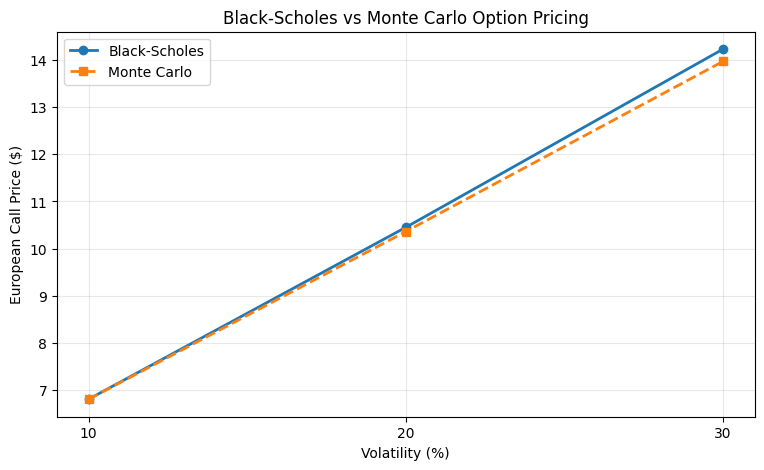

In [12]:
plt.figure(figsize=(9, 5))

# Black-Scholes analytical prices
plt.plot(
    mc_df["Volatility (%)"],
    mc_df["Black-Scholes ($)"],
    marker="o",
    linewidth=2,
    label="Black-Scholes"
)

# Monte Carlo estimated prices
plt.plot(
    mc_df["Volatility (%)"],
    mc_df["Monte Carlo ($)"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Monte Carlo"
)

plt.xlabel("Volatility (%)")
plt.ylabel("European Call Price ($)")
plt.title("Black-Scholes vs Monte Carlo Option Pricing")

plt.xticks(mc_df["Volatility (%)"])
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 13. Monte Carlo Error and Confidence Interval

Monte Carlo simulation estimates option prices using random samples. Therefore, the estimated price may differ from the exact Black–Scholes price.

### 13.1 Standard Error

The standard error measures the uncertainty of the Monte Carlo estimate.

$$
SE = \frac{s_X}{\sqrt{N}}
$$

where $s_X$ is the sample standard deviation of the discounted option payoffs and $N$ is the number of simulated paths.

### 13.2 Confidence Interval

We construct an approximate 95% confidence interval:

$$
CI_{95\%} =
\hat{C}_0 \pm 1.96 \times SE
$$

### Objective

- Calculate the Monte Carlo standard error.
- Construct a 95% confidence interval.
- Compare the estimated price against the Black–Scholes benchmark.
- Examine how simulation uncertainty changes across volatility scenarios.

In [13]:
# Calculate Monte Carlo confidence intervals

ci_results = []

for sigma in sigmas:

    ST = stock_paths[sigma][:, -1]

    # Discounted European call payoffs
    discounted_payoffs = np.exp(-r * T) * np.maximum(ST - K, 0)

    # Monte Carlo estimate
    mc_price = np.mean(discounted_payoffs)

    # Standard error
    se = np.std(discounted_payoffs, ddof=1) / np.sqrt(n_paths)

    # 95% confidence interval
    ci_lower = mc_price - 1.96 * se
    ci_upper = mc_price + 1.96 * se

    # Black-Scholes benchmark
    bs_price = black_scholes_call(S0, K, T, r, sigma)

    ci_results.append({
        "Volatility (%)": sigma * 100,
        "BS Price": bs_price,
        "MC Price": mc_price,
        "Standard Error": se,
        "CI Lower": ci_lower,
        "CI Upper": ci_upper,
        "BS Inside CI": ci_lower <= bs_price <= ci_upper
    })

ci_df = pd.DataFrame(ci_results)

print(ci_df.round(4))

   Volatility (%)  BS Price  MC Price  Standard Error  CI Lower  CI Upper  \
0            10.0    6.8050    6.8030          0.2381    6.3363    7.2697   
1            20.0   10.4506   10.3612          0.4487    9.4819   11.2406   
2            30.0   14.2313   13.9710          0.6798   12.6386   15.3034   

   BS Inside CI  
0          True  
1          True  
2          True  


## 14. Monte Carlo Convergence Analysis

Monte Carlo accuracy generally improves as the number of simulated paths increases.

According to the Law of Large Numbers:

$$
\hat{C}_N \xrightarrow{a.s.} C_0
\quad \text{as } N \to \infty
$$

The standard error decreases approximately at the rate:

$$
SE \propto \frac{1}{\sqrt{N}}
$$

### Objective

We investigate how the European call price estimate changes as the number of simulations increases:

$$
N \in \{100, 500, 1000, 5000, 10000, 50000\}
$$

We use a fixed volatility of $\sigma = 20\%$ and compare Monte Carlo estimates against the Black–Scholes theoretical price.

In [14]:
# Monte Carlo convergence parameters
sigma = 0.20
simulation_sizes = [100, 500, 1000, 5000, 10000, 50000]

np.random.seed(42)

# Generate terminal stock prices under risk-neutral GBM
Z = np.random.normal(size=max(simulation_sizes))

ST = S0 * np.exp(
    (r - 0.5 * sigma**2) * T
    + sigma * np.sqrt(T) * Z
)

# Discounted European call payoffs
payoffs = np.exp(-r * T) * np.maximum(ST - K, 0)

# Black-Scholes benchmark
bs_price = black_scholes_call(S0, K, T, r, sigma)

convergence_results = []

for N in simulation_sizes:
    mc_price = np.mean(payoffs[:N])

    convergence_results.append({
        "Simulations": N,
        "Monte Carlo Price": mc_price,
        "Black-Scholes Price": bs_price,
        "Absolute Error": abs(mc_price - bs_price)
    })

convergence_df = pd.DataFrame(convergence_results)

print(convergence_df.round(4))

   Simulations  Monte Carlo Price  Black-Scholes Price  Absolute Error
0          100             8.1600              10.4506          2.2906
1          500            10.3776              10.4506          0.0729
2         1000            10.5166              10.4506          0.0660
3         5000            10.4850              10.4506          0.0344
4        10000            10.4502              10.4506          0.0004
5        50000            10.4462              10.4506          0.0044


## 15. Visualization of Monte Carlo Convergence

We visualize how the Monte Carlo estimate approaches the Black–Scholes theoretical price as the number of simulations increases.

The comparison uses:

$$
\sigma = 20\%
$$

The Black–Scholes price serves as the analytical benchmark.

We expect the Monte Carlo estimate to become more stable as the number of simulations increases, although convergence is not necessarily monotonic.

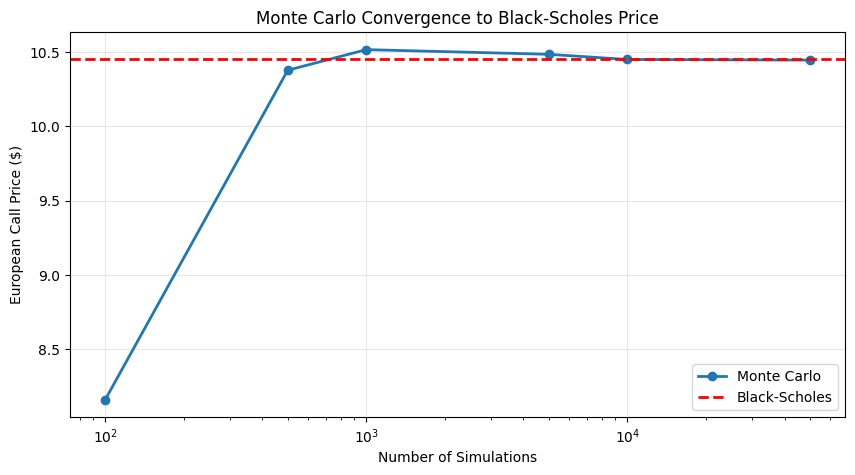

In [15]:
plt.figure(figsize=(10, 5))

# Monte Carlo estimates
plt.plot(
    convergence_df["Simulations"],
    convergence_df["Monte Carlo Price"],
    marker="o",
    linewidth=2,
    label="Monte Carlo"
)

# Black-Scholes benchmark
plt.axhline(
    y=bs_price,
    color="red",
    linestyle="--",
    linewidth=2,
    label="Black-Scholes"
)

plt.xlabel("Number of Simulations")
plt.ylabel("European Call Price ($)")
plt.title("Monte Carlo Convergence to Black-Scholes Price")

plt.xscale("log")
plt.legend()
plt.grid(alpha=0.3)

plt.show()

## 16. Monte Carlo Absolute Pricing Error

We investigate how the absolute pricing error changes as the number of Monte Carlo simulations increases.

The absolute error is defined as:

$$
\text{Absolute Error}_N = |\hat{C}_N - C_{BS}|
$$

where:

- $\hat{C}_N$: Monte Carlo estimated option price
- $C_{BS}$: Black–Scholes analytical price
- $N$: Number of simulated paths

### Objective

Visualize the relationship between simulation size and pricing error.

As $N$ increases, the error generally tends to decrease, but it may fluctuate due to randomness.

The typical Monte Carlo estimation error decreases at the rate:

$$
O(N^{-1/2})
$$

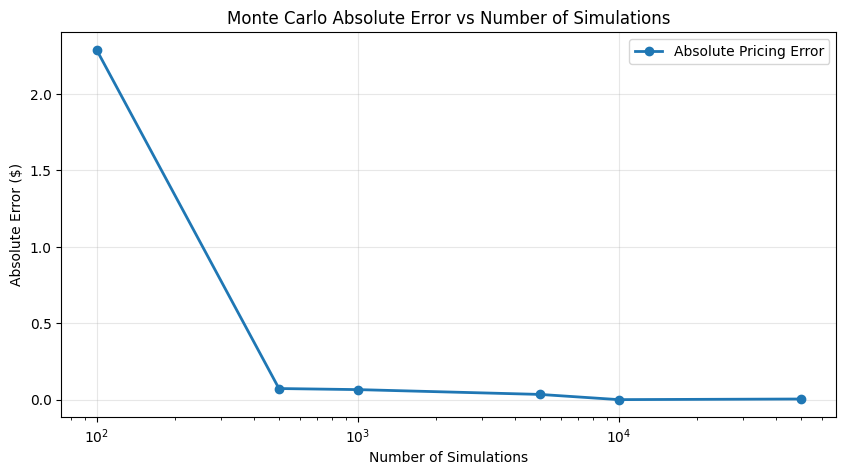

In [16]:
plt.figure(figsize=(10, 5))

plt.plot(
    convergence_df["Simulations"],
    convergence_df["Absolute Error"],
    marker="o",
    linewidth=2,
    label="Absolute Pricing Error"
)

plt.xlabel("Number of Simulations")
plt.ylabel("Absolute Error ($)")
plt.title("Monte Carlo Absolute Error vs Number of Simulations")

plt.xscale("log")
plt.grid(alpha=0.3)
plt.legend()

plt.show()

## 17. Volatility Sensitivity Comparison

We compare how European call option prices change with volatility under two pricing methods:

1. Black–Scholes analytical pricing.
2. Monte Carlo simulation.

We consider:

$$
\sigma \in \{10\%,20\%,30\%\}
$$

### Price Sensitivity

For two volatility levels, the change in option price is:

$$
\Delta C = C(\sigma_2)-C(\sigma_1)
$$

We investigate whether both pricing methods produce similar price changes as volatility increases.

### Objective

- Compare the price changes from 10% to 20% volatility.
- Compare the price changes from 20% to 30% volatility.
- Evaluate the difference between analytical and simulated sensitivities.

In [17]:
# Compare price changes across volatility scenarios
sensitivity_df = mc_df.copy()

# Absolute price changes
sensitivity_df["BS Price Change ($)"] = (
    sensitivity_df["Black-Scholes ($)"].diff()
)

sensitivity_df["MC Price Change ($)"] = (
    sensitivity_df["Monte Carlo ($)"].diff()
)

# Difference between estimated price changes
sensitivity_df["Sensitivity Difference ($)"] = (
    sensitivity_df["MC Price Change ($)"]
    - sensitivity_df["BS Price Change ($)"]
)

print(sensitivity_df[[
    "Volatility (%)",
    "BS Price Change ($)",
    "MC Price Change ($)",
    "Sensitivity Difference ($)"
]].round(4))

   Volatility (%)  BS Price Change ($)  MC Price Change ($)  \
0            10.0                  NaN                  NaN   
1            20.0               3.6456               3.5582   
2            30.0               3.7807               3.6097   

   Sensitivity Difference ($)  
0                         NaN  
1                     -0.0874  
2                     -0.1709  


## 18. Visualization of Volatility Sensitivity

We compare the changes in European call option prices obtained from Black–Scholes and Monte Carlo simulation.

For each volatility interval:

$$
\Delta C = C(\sigma_2)-C(\sigma_1)
$$

We consider two intervals:

- 10% to 20% volatility
- 20% to 30% volatility

### Objective

Determine whether Monte Carlo simulation captures the same volatility sensitivity as the Black–Scholes analytical model.

Both methods should produce similar results, although Monte Carlo estimates contain sampling error.

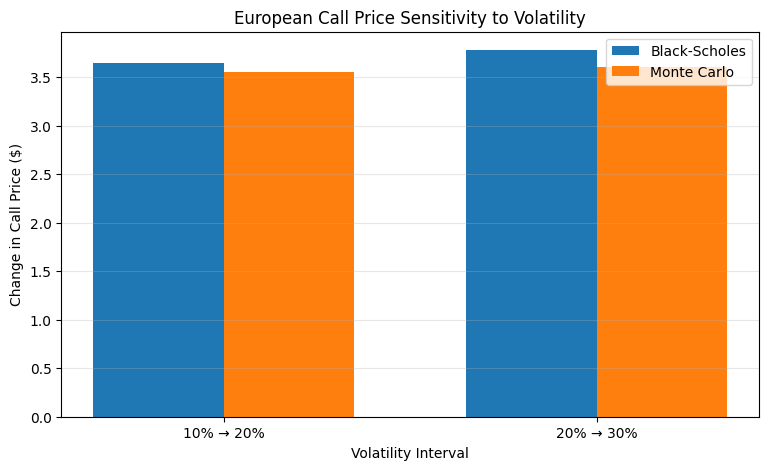

In [18]:
# Prepare volatility intervals
intervals = ["10% → 20%", "20% → 30%"]

bs_changes = sensitivity_df["BS Price Change ($)"].iloc[1:]
mc_changes = sensitivity_df["MC Price Change ($)"].iloc[1:]

# Bar chart
x = np.arange(len(intervals))
width = 0.35

plt.figure(figsize=(9, 5))

plt.bar(
    x - width / 2,
    bs_changes,
    width,
    label="Black-Scholes"
)

plt.bar(
    x + width / 2,
    mc_changes,
    width,
    label="Monte Carlo"
)

plt.xticks(x, intervals)
plt.xlabel("Volatility Interval")
plt.ylabel("Change in Call Price ($)")
plt.title("European Call Price Sensitivity to Volatility")

plt.legend()
plt.grid(axis="y", alpha=0.3)

plt.show()

## 19. Conclusion: European Call Option Volatility Analysis

### 19.1 Impact of Volatility

We investigated European call option prices using the Black–Scholes analytical model and Monte Carlo simulation.

The volatility scenarios were:

$$
\sigma \in \{10\%,20\%,30\%\}
$$

All other model parameters remained constant.

Under the Black–Scholes model, the European call option price increases as volatility increases.

This occurs because higher volatility increases the potential for large positive stock price movements, while the call option payoff cannot fall below zero.

### 19.2 Black–Scholes vs Monte Carlo

The Black–Scholes formula provides an analytical benchmark, while Monte Carlo estimates the discounted expected payoff:

$$
C_0=e^{-rT}\mathbb{E}^{\mathbb Q}[(S_T-K)^+]
$$

Differences between the two estimates arise from Monte Carlo sampling error.

### 19.3 Monte Carlo Convergence

Increasing the number of simulations generally improves the precision of Monte Carlo estimates.

The standard error decreases approximately at the rate:

$$
SE=O(N^{-1/2})
$$

However, the absolute error does not necessarily decrease after every increase in simulation size.

### 19.4 Volatility Sensitivity

Vega measures the sensitivity of an option price to volatility:

$$
\text{Vega}=\frac{\partial C}{\partial \sigma}
$$

A positive Vega indicates that increasing volatility increases the European call option price.

### 19.5 Conclusion

Our European option experiment establishes a benchmark for the next stage of the project: Asian option pricing.

We will use the same volatility scenarios, risk-neutral stock price model, and Monte Carlo framework to compare how European and Asian call options respond to volatility.

In [19]:
# Final European option comparison
final_df = mc_df.copy()

final_df["Vega"] = [
    black_scholes_vega(S0, K, T, r, sigma)
    for sigma in sigmas
]

final_df["Relative Error (%)"] = (
    final_df["Absolute Error ($)"]
    / final_df["Black-Scholes ($)"] * 100
)

print("FINAL EUROPEAN OPTION RESULTS")
display(final_df.round(4))

FINAL EUROPEAN OPTION RESULTS


,Volatility (%),Black-Scholes ($),Monte Carlo ($),Absolute Error ($),Vega,Relative Error (%)
0,10.0,6.8050,6.8030,0.0019,34.2944,0.0286
1,20.0,10.4506,10.3612,0.0894,37.5240,0.8550
2,30.0,14.2313,13.9710,0.2603,37.9433,1.8289


## 20. 3D Visualization of European Call Option Price

To enrich the volatility analysis, we create a 3D surface of the European call option price under the Black–Scholes model.

The option value is represented as:

$$
C = C(S,\sigma)
$$

where:

- $S$: stock price
- $\sigma$: volatility

This visualization helps us observe how the European call price changes jointly with the underlying stock price and volatility.

It also connects with the Black–Scholes PDE, since the option price is a function of the state variable $S$ and model parameters such as $\sigma$.

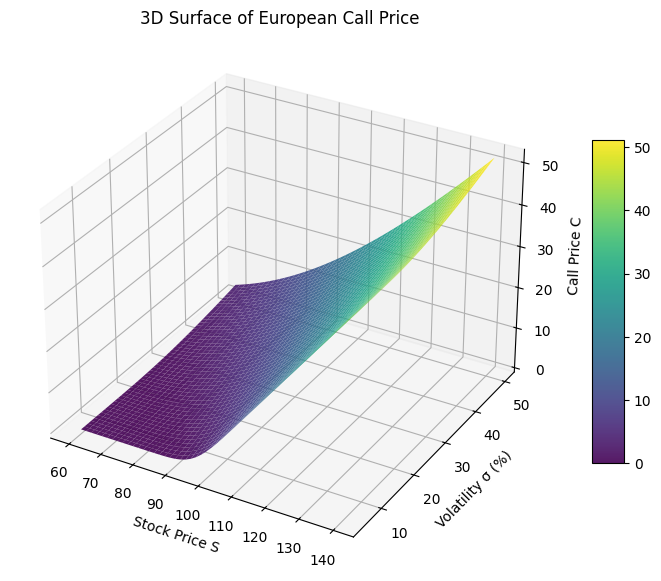

In [20]:
from mpl_toolkits.mplot3d import Axes3D

# Grid for stock price and volatility
S_values = np.linspace(60, 140, 50)
sigma_values = np.linspace(0.05, 0.50, 50)

S_grid, sigma_grid = np.meshgrid(S_values, sigma_values)

# Compute option prices on the grid
C_grid = np.zeros_like(S_grid)

for i in range(S_grid.shape[0]):
    for j in range(S_grid.shape[1]):
        C_grid[i, j] = black_scholes_call(
            S_grid[i, j], K, T, r, sigma_grid[i, j]
        )

# 3D surface plot
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    S_grid, sigma_grid * 100, C_grid,
    cmap='viridis',
    edgecolor='none',
    alpha=0.9
)

ax.set_xlabel("Stock Price S")
ax.set_ylabel("Volatility σ (%)")
ax.set_zlabel("Call Price C")
ax.set_title("3D Surface of European Call Price")

fig.colorbar(surf, shrink=0.6, aspect=10)
plt.show()

## 21. 3D Visualization of European Call Price with Respect to Stock Price and Time

We also visualize the European call option price as a function of:

$$
C = C(S,\tau)
$$

where:

- $S$: stock price
- $\tau$: time to maturity

This surface is useful because the Black–Scholes PDE describes how the option value evolves over time.

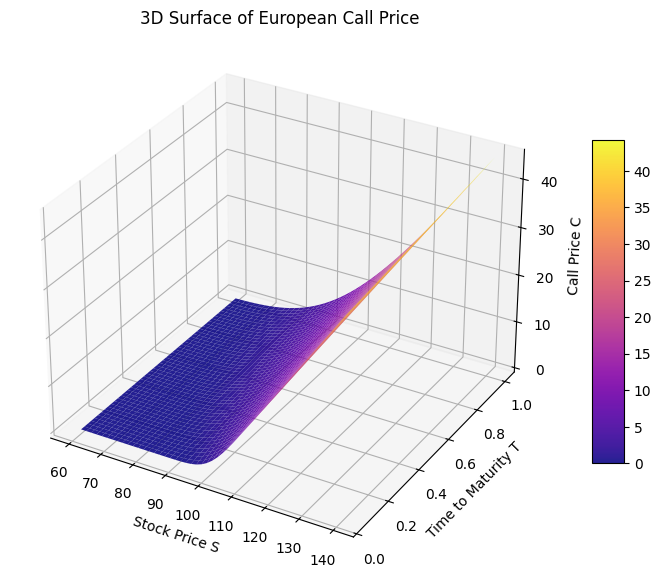

In [21]:
# Grid for stock price and time to maturity
S_values = np.linspace(60, 140, 50)
T_values = np.linspace(0.05, 1.0, 50)

S_grid, T_grid = np.meshgrid(S_values, T_values)

# Fix volatility
sigma_fixed = 0.20

C_time_grid = np.zeros_like(S_grid)

for i in range(S_grid.shape[0]):
    for j in range(S_grid.shape[1]):
        C_time_grid[i, j] = black_scholes_call(
            S_grid[i, j], K, T_grid[i, j], r, sigma_fixed
        )

# 3D surface plot
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    S_grid, T_grid, C_time_grid,
    cmap='plasma',
    edgecolor='none',
    alpha=0.9
)

ax.set_xlabel("Stock Price S")
ax.set_ylabel("Time to Maturity T")
ax.set_zlabel("Call Price C")
ax.set_title("3D Surface of European Call Price")

fig.colorbar(surf, shrink=0.6, aspect=10)
plt.show()

## 22. 3D Visualization of Vega

Vega measures the sensitivity of the option price to volatility:

$$
\text{Vega} = \frac{\partial C}{\partial \sigma}
$$

We construct a 3D surface of Vega as a function of stock price and volatility.

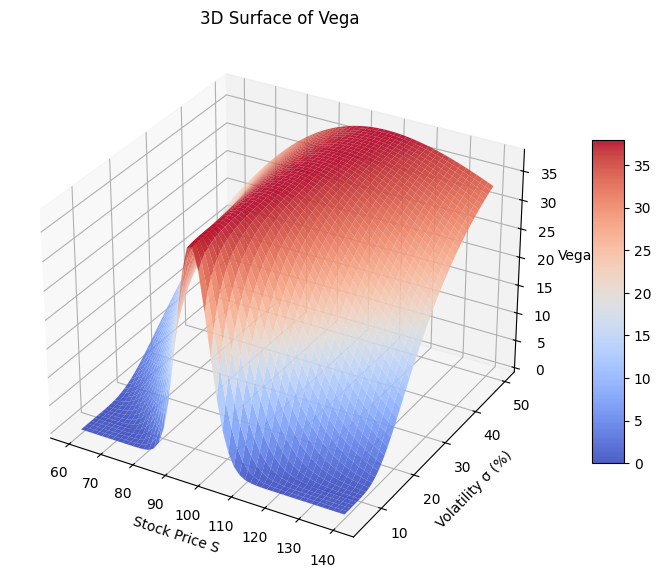

In [22]:
# Grid for stock price and volatility
S_values = np.linspace(60, 140, 50)
sigma_values = np.linspace(0.05, 0.50, 50)

S_grid, sigma_grid = np.meshgrid(S_values, sigma_values)

vega_grid = np.zeros_like(S_grid)

for i in range(S_grid.shape[0]):
    for j in range(S_grid.shape[1]):
        vega_grid[i, j] = black_scholes_vega(
            S_grid[i, j], K, T, r, sigma_grid[i, j]
        )

# 3D surface plot
fig = plt.figure(figsize=(11, 7))
ax = fig.add_subplot(111, projection='3d')

surf = ax.plot_surface(
    S_grid, sigma_grid * 100, vega_grid,
    cmap='coolwarm',
    edgecolor='none',
    alpha=0.9
)

ax.set_xlabel("Stock Price S")
ax.set_ylabel("Volatility σ (%)")
ax.set_zlabel("Vega")
ax.set_title("3D Surface of Vega")

fig.colorbar(surf, shrink=0.6, aspect=10)
plt.show()

### Interpretation of the 3D Surface

The 3D surface shows that the European call option price increases as the stock price increases and as volatility increases.

For higher stock prices, the option is more likely to finish in the money, which increases its value.

For higher volatility, the uncertainty of future stock prices becomes larger, increasing the probability of large favorable upward movements. Since the call payoff is bounded below by zero, this asymmetry makes the option more valuable.

This visualization supports the analytical findings of the Black–Scholes model and provides a graphical interpretation of the option value as a solution surface related to the Black–Scholes PDE.

## 23. Numerical Solution of the Black–Scholes PDE

The Black–Scholes PDE for a European call option is:

$$
\frac{\partial C}{\partial t}
+\frac{1}{2}\sigma^2 S^2\frac{\partial^2 C}{\partial S^2}
+rS\frac{\partial C}{\partial S}
-rC=0
$$

The terminal condition at maturity is:

$$
C(S,T)=\max(S-K,0)
$$

### Time Transformation

Let $\tau=T-t$ denote the remaining time to maturity.

Then:

$$
\frac{\partial C}{\partial \tau}
=
\frac{1}{2}\sigma^2 S^2\frac{\partial^2 C}{\partial S^2}
+rS\frac{\partial C}{\partial S}
-rC
$$

### Crank–Nicolson Method

We approximate the spatial derivatives using central finite differences and average the PDE operator between two consecutive time steps:

$$
\frac{C^{n+1}-C^n}{\Delta\tau}
=
\frac{1}{2}L(C^{n+1})
+
\frac{1}{2}L(C^n)
$$

where:

$$
L(C)=
\frac{1}{2}\sigma^2S^2 C_{SS}
+rS C_S-rC
$$

The resulting linear system is:

$$
\left(I-\frac{\Delta\tau}{2}L\right)C^{n+1}
=
\left(I+\frac{\Delta\tau}{2}L\right)C^n
$$

### Objective

- Solve the Black–Scholes PDE numerically.
- Compute European call prices for $\sigma=10\%,20\%,30\%$.
- Compare finite difference prices with the analytical Black–Scholes prices.
- Evaluate numerical pricing errors.

In [23]:
from scipy.linalg import solve_banded

def crank_nicolson_call(S0, K, T, r, sigma, Smax=400, M=400, N=400):

    dS = Smax / M
    dt = T / N

    S = np.linspace(0, Smax, M + 1)

    # Terminal payoff
    V = np.maximum(S - K, 0)

    # Interior grid indices
    i = np.arange(1, M)

    # Black-Scholes spatial operator coefficients
    a = 0.5 * sigma**2 * i**2 - 0.5 * r * i
    b = -sigma**2 * i**2 - r
    c = 0.5 * sigma**2 * i**2 + 0.5 * r * i

    # Crank-Nicolson matrices
    lower_A = -0.5 * dt * a[1:]
    diag_A = 1 - 0.5 * dt * b
    upper_A = -0.5 * dt * c[:-1]

    lower_B = 0.5 * dt * a[1:]
    diag_B = 1 + 0.5 * dt * b
    upper_B = 0.5 * dt * c[:-1]

    # Banded matrix for efficient solving
    ab = np.zeros((3, M - 1))
    ab[0, 1:] = upper_A
    ab[1, :] = diag_A
    ab[2, :-1] = lower_A

    # Time stepping
    for n in range(N):

        tau_new = (n + 1) * dt

        # Boundary conditions
        V_left = 0
        V_right = Smax - K * np.exp(-r * tau_new)

        rhs = diag_B * V[1:-1]

        rhs[1:] += lower_B * V[1:-2]
        rhs[:-1] += upper_B * V[2:-1]

        # Upper boundary contribution
        rhs[-1] += 0.5 * dt * c[-1] * (
            V[-1] + V_right
        )

        # Solve linear system
        V_new = solve_banded((1, 1), ab, rhs)

        V[0] = V_left
        V[-1] = V_right
        V[1:-1] = V_new

    # Interpolate price at S0
    price = np.interp(S0, S, V)

    return price

In [24]:
fdm_results = []

for sigma in sigmas:

    bs_price = black_scholes_call(S0, K, T, r, sigma)

    fdm_price = crank_nicolson_call(
        S0, K, T, r, sigma
    )

    fdm_results.append({
        "Volatility (%)": sigma * 100,
        "Black-Scholes ($)": bs_price,
        "FDM ($)": fdm_price,
        "Absolute Error ($)": abs(fdm_price - bs_price)
    })

fdm_df = pd.DataFrame(fdm_results)

display(fdm_df.round(6))

,Volatility (%),Black-Scholes ($),FDM ($),Absolute Error ($)
0,10.0,6.804958,6.799597,0.005361
1,20.0,10.450584,10.448114,0.002470
2,30.0,14.231255,14.229667,0.001588


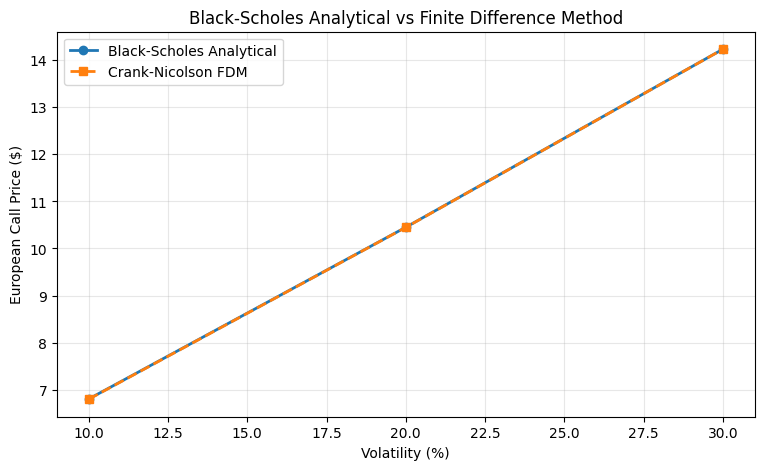

In [25]:
plt.figure(figsize=(9, 5))

plt.plot(
    fdm_df["Volatility (%)"],
    fdm_df["Black-Scholes ($)"],
    marker="o",
    linewidth=2,
    label="Black-Scholes Analytical"
)

plt.plot(
    fdm_df["Volatility (%)"],
    fdm_df["FDM ($)"],
    marker="s",
    linestyle="--",
    linewidth=2,
    label="Crank-Nicolson FDM"
)

plt.xlabel("Volatility (%)")
plt.ylabel("European Call Price ($)")
plt.title("Black-Scholes Analytical vs Finite Difference Method")

plt.legend()
plt.grid(alpha=0.3)
plt.show()

## 24. 3D Numerical Solution of the Black–Scholes PDE

We solve the Black–Scholes PDE numerically and visualize the option value:

$$
C = C(S,\tau)
$$

where:

- $S$: Underlying stock price
- $\tau=T-t$: Remaining time to maturity
- $C$: European call option value

The PDE in time-to-maturity coordinates is:

$$
\frac{\partial C}{\partial \tau}
=
\frac12\sigma^2 S^2\frac{\partial^2 C}{\partial S^2}
+rS\frac{\partial C}{\partial S}-rC
$$

The initial condition in $\tau$ is the payoff:

$$
C(S,0)=\max(S-K,0)
$$

We use $\sigma=20\%$ and construct a 3D surface from the numerical finite difference solution.

In [26]:
from scipy.linalg import solve_banded

def crank_nicolson_surface(K, T, r, sigma,
                          Smax=250, M=200, N=200):

    S = np.linspace(0, Smax, M + 1)
    tau = np.linspace(0, T, N + 1)

    dt = T / N
    i = np.arange(1, M)

    # PDE coefficients
    a = 0.5 * sigma**2 * i**2 - 0.5 * r * i
    b = -sigma**2 * i**2 - r
    c = 0.5 * sigma**2 * i**2 + 0.5 * r * i

    # Crank-Nicolson matrices
    lower_A = -0.5 * dt * a[1:]
    diag_A = 1 - 0.5 * dt * b
    upper_A = -0.5 * dt * c[:-1]

    lower_B = 0.5 * dt * a[1:]
    diag_B = 1 + 0.5 * dt * b
    upper_B = 0.5 * dt * c[:-1]

    ab = np.zeros((3, M - 1))
    ab[0, 1:] = upper_A
    ab[1, :] = diag_A
    ab[2, :-1] = lower_A

    # Store solution at every time step
    V = np.zeros((N + 1, M + 1))
    V[0, :] = np.maximum(S - K, 0)

    for n in range(N):

        rhs = diag_B * V[n, 1:-1]

        rhs[1:] += lower_B * V[n, 1:-2]
        rhs[:-1] += upper_B * V[n, 2:-1]

        # Boundary at S = Smax
        upper_old = Smax - K * np.exp(-r * tau[n])
        upper_new = Smax - K * np.exp(-r * tau[n+1])

        rhs[-1] += 0.5 * dt * c[-1] * (
            upper_old + upper_new
        )

        V[n+1, 1:-1] = solve_banded((1, 1), ab, rhs)

        V[n+1, 0] = 0
        V[n+1, -1] = upper_new

    return S, tau, V


# Calculate numerical PDE surface
sigma_fixed = 0.20

S_fdm, tau_fdm, V_fdm = crank_nicolson_surface(
    K, T, r, sigma_fixed
)

print("PDE numerical surface calculated.")
print("Surface shape:", V_fdm.shape)

PDE numerical surface calculated.
Surface shape: (201, 201)


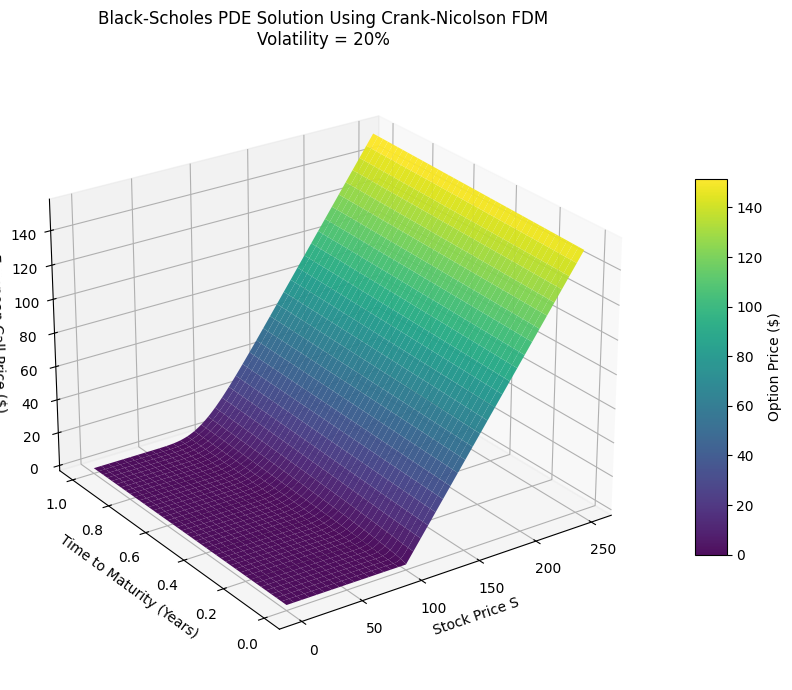

In [27]:
# Create meshgrid
S_mesh, tau_mesh = np.meshgrid(S_fdm, tau_fdm)

fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    S_mesh,
    tau_mesh,
    V_fdm,
    cmap="viridis",
    edgecolor="none",
    alpha=0.95
)

ax.set_xlabel("Stock Price S")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("European Call Price ($)")

ax.set_title(
    "Black-Scholes PDE Solution Using Crank-Nicolson FDM\n"
    "Volatility = 20%"
)

ax.view_init(elev=25, azim=-125)

fig.colorbar(
    surf,
    ax=ax,
    shrink=0.6,
    aspect=12,
    label="Option Price ($)"
)

plt.tight_layout()
plt.show()

### Interpretation

The 3D surface represents the numerical solution of the Black–Scholes PDE.

**Stock price effect:** The European call option becomes more valuable as the underlying stock price increases.

**Time effect:** For a non-dividend-paying stock with a nonnegative risk-free rate, a longer time to maturity increases or preserves the European call option value.

**Terminal payoff:** When time to maturity approaches zero, the option value approaches:

$$
C(S,0)=\max(S-K,0)
$$

The Crank–Nicolson method approximates this pricing surface by discretizing both the stock price and time dimensions.

This provides a numerical connection between option pricing, partial differential equations, and stochastic calculus.

## 25. Impact of Volatility on the Black–Scholes PDE Surface

We investigate the numerical solution:

$$
C = C(S,\tau;\sigma)
$$

under three volatility scenarios:

$$
\sigma \in \{0.10,0.20,0.30\}
$$

The Black–Scholes PDE is:

$$
\frac{\partial C}{\partial \tau}
=
\frac12\sigma^2 S^2\frac{\partial^2 C}{\partial S^2}
+rS\frac{\partial C}{\partial S}
-rC
$$

### Objective

- Compare the numerical pricing surfaces at different volatility levels.
- Observe how the option price changes as volatility increases.
- Understand how volatility affects the curvature of the pricing surface.
- Connect the results to the Black–Scholes PDE.

All other parameters remain constant.

In [28]:
# Compute PDE surfaces for three volatility scenarios

pde_surfaces = {}

for sigma in sigmas:

    S_grid_fdm, tau_grid_fdm, V_grid_fdm = crank_nicolson_surface(
        K, T, r, sigma,
        Smax=250,
        M=200,
        N=200
    )

    pde_surfaces[sigma] = V_grid_fdm

S_mesh, tau_mesh = np.meshgrid(S_grid_fdm, tau_grid_fdm)

print("All three PDE surfaces computed.")

All three PDE surfaces computed.


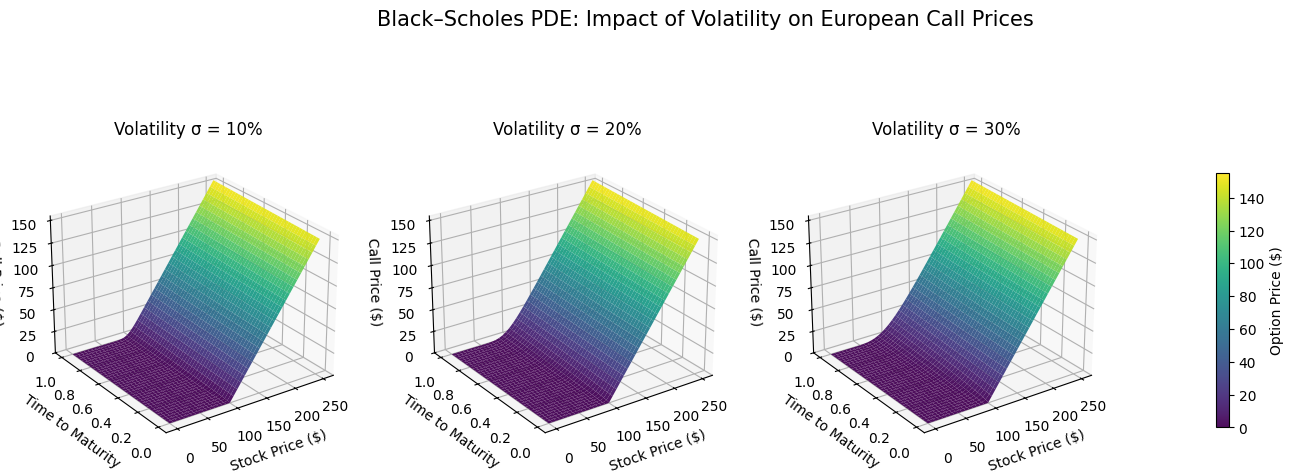

In [29]:
fig = plt.figure(figsize=(18, 6))

# Common color scale for fair comparison
vmin = min(V.min() for V in pde_surfaces.values())
vmax = max(V.max() for V in pde_surfaces.values())

for idx, sigma in enumerate(sigmas, start=1):

    ax = fig.add_subplot(1, 3, idx, projection="3d")

    surf = ax.plot_surface(
        S_mesh,
        tau_mesh,
        pde_surfaces[sigma],
        cmap="viridis",
        vmin=vmin,
        vmax=vmax,
        edgecolor="none",
        alpha=0.95
    )

    ax.set_title(f"Volatility σ = {sigma:.0%}")
    ax.set_xlabel("Stock Price ($)")
    ax.set_ylabel("Time to Maturity")
    ax.set_zlabel("Call Price ($)")

    ax.set_zlim(vmin, vmax)
    ax.view_init(elev=25, azim=-125)

fig.suptitle(
    "Black–Scholes PDE: Impact of Volatility on European Call Prices",
    fontsize=15
)

fig.colorbar(
    surf,
    ax=fig.axes,
    shrink=0.55,
    pad=0.08,
    label="Option Price ($)"
)

plt.show()

### 25.1 Interpretation of the PDE Surfaces

The three surfaces illustrate how volatility affects European call option prices.

**At 10% volatility:**

Stock price fluctuations are relatively small, and the option pricing surface transitions more sharply around the strike price.

**At 20% volatility:**

The pricing surface becomes smoother around the strike, and the option generally has a higher value.

**At 30% volatility:**

Higher uncertainty produces a larger option value, especially near the strike price and for longer times to maturity.

### 25.2 Connection to the Black–Scholes PDE

The volatility parameter appears in the second-order derivative term:

$$
\frac12\sigma^2 S^2\frac{\partial^2 C}{\partial S^2}
$$

This term controls the diffusion component of the pricing equation.

As volatility increases, the diffusion coefficient increases, changing the curvature and evolution of the option pricing surface.

### 25.3 Conclusion

The numerical PDE surfaces confirm the positive relationship between volatility and European call option prices.

These findings provide a basis for comparing volatility sensitivity between European and Asian options.

## 26. Difference Between PDE Pricing Surfaces

We investigate the impact of changing volatility from 10% to 30% on European call option prices.

Define the price difference:

$$
\Delta C(S,\tau)
=
C(S,\tau;\sigma=0.30)
-
C(S,\tau;\sigma=0.10)
$$

where:

- $S$: Underlying stock price
- $\tau$: Time to maturity
- $\Delta C$: Difference in European call prices

### Objective

Visualize where volatility has the greatest impact on the European call price.

The comparison uses the same stock price grid, time grid, strike price, and risk-free rate.

In [30]:
# Difference between 30% and 10% volatility
V_diff = pde_surfaces[0.30] - pde_surfaces[0.10]

print("Minimum price difference:", V_diff.min())
print("Maximum price difference:", V_diff.max())

Minimum price difference: -1.8658568023965927e-09
Maximum price difference: 7.581528580106723


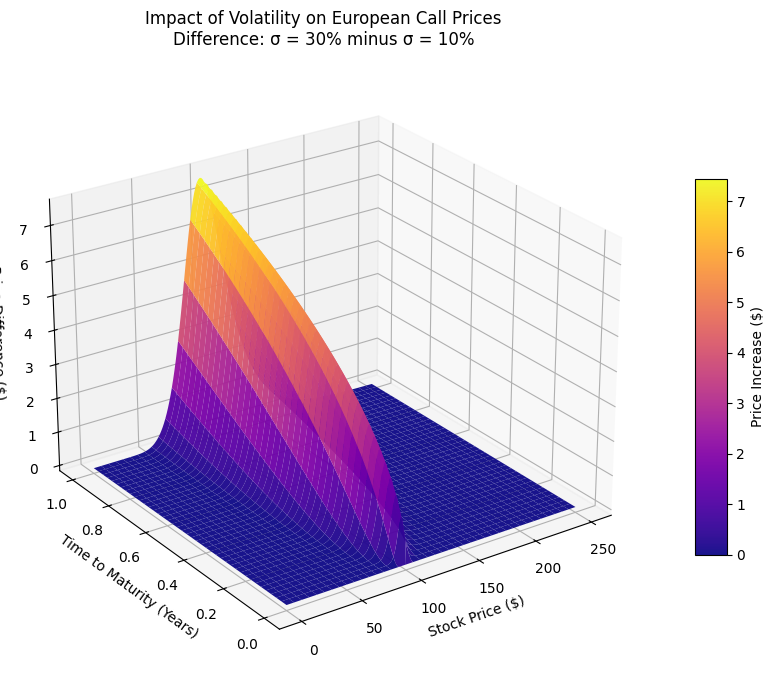

In [31]:
fig = plt.figure(figsize=(12, 7))
ax = fig.add_subplot(111, projection="3d")

surf = ax.plot_surface(
    S_mesh,
    tau_mesh,
    V_diff,
    cmap="plasma",
    edgecolor="none",
    alpha=0.95
)

ax.set_xlabel("Stock Price ($)")
ax.set_ylabel("Time to Maturity (Years)")
ax.set_zlabel("Price Difference ($)")

ax.set_title(
    "Impact of Volatility on European Call Prices\n"
    "Difference: σ = 30% minus σ = 10%"
)

ax.view_init(elev=25, azim=-125)

fig.colorbar(
    surf,
    ax=ax,
    shrink=0.6,
    aspect=12,
    label="Price Increase ($)"
)

plt.tight_layout()
plt.show()

### 26.1 Interpretation

The difference surface illustrates how increasing volatility from 10% to 30% affects the European call option price.

**Near the strike price:**

Volatility typically has a substantial impact because the option's payoff is highly sensitive to whether the stock finishes above or below the strike.

**Deep in-the-money or out-of-the-money regions:**

The effect of volatility generally becomes smaller, particularly when the remaining time to maturity is short.

**At maturity:**

The difference approaches zero because the terminal payoff is independent of volatility:

$$
C(S,0)=\max(S-K,0)
$$

### 26.2 Mathematical Interpretation

The price difference can be expressed using Vega:

$$
C(S,\tau;0.30)-C(S,\tau;0.10)
=
\int_{0.10}^{0.30}
\frac{\partial C}{\partial \sigma}(S,\tau;\sigma)
\,d\sigma
$$

Thus, the difference surface represents the accumulated effect of Vega across the volatility interval.

### Conclusion

The difference surface provides a direct visualization of volatility sensitivity across stock prices and times to maturity.

It complements the earlier 2D volatility analysis and demonstrates how PDE numerical methods can be used to investigate option pricing sensitivity.

## 27. Heatmap of Volatility Sensitivity

We investigate how European call option prices change when volatility increases from 10% to 30%.

The price difference is defined as:

$$
\Delta C(S,\tau)
=
C(S,\tau;0.30)-C(S,\tau;0.10)
$$

where:

- $S$: Underlying stock price
- $\tau$: Time to maturity
- $\Delta C$: Change in option price

### Objective

- Identify regions with the greatest volatility sensitivity.
- Examine the relationship between stock price, time to maturity, and volatility.
- Visualize the results of the Black–Scholes PDE numerical solution.

Higher heatmap values indicate a larger increase in option price when volatility rises from 10% to 30%.

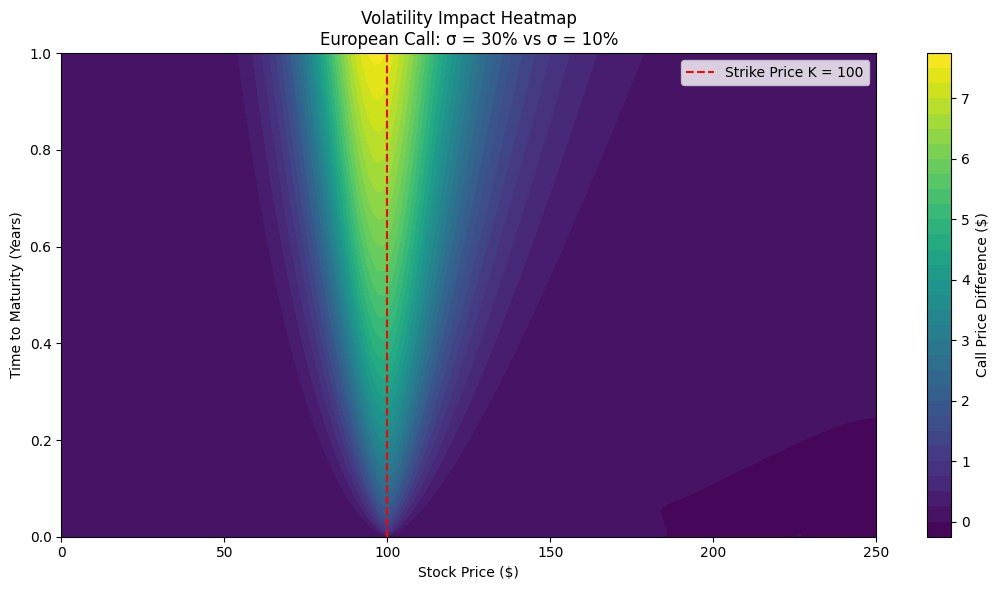

In [32]:
plt.figure(figsize=(11, 6))

heatmap = plt.contourf(
    S_mesh,
    tau_mesh,
    V_diff,
    levels=30,
    cmap="viridis"
)

plt.colorbar(
    heatmap,
    label="Call Price Difference ($)"
)

plt.axvline(
    K,
    color="red",
    linestyle="--",
    linewidth=1.5,
    label=f"Strike Price K = {K}"
)

plt.xlabel("Stock Price ($)")
plt.ylabel("Time to Maturity (Years)")
plt.title(
    "Volatility Impact Heatmap\n"
    "European Call: σ = 30% vs σ = 10%"
)

plt.legend()
plt.tight_layout()
plt.show()

In [33]:
# Find the largest impact of volatility
max_index = np.unravel_index(
    np.argmax(V_diff),
    V_diff.shape
)

max_difference = V_diff[max_index]
max_stock_price = S_mesh[max_index]
max_maturity = tau_mesh[max_index]

print(f"Maximum Price Difference: ${max_difference:.4f}")
print(f"Stock Price: ${max_stock_price:.2f}")
print(f"Time to Maturity: {max_maturity:.4f} years")

Maximum Price Difference: $7.5815
Stock Price: $96.25
Time to Maturity: 1.0000 years


### 27.1 Interpretation

The heatmap illustrates the impact of volatility on European call prices across different stock prices and times to maturity.

**High-impact regions:**

Larger price differences typically occur where the option has substantial sensitivity to volatility, often near the at-the-money region.

**Low-impact regions:**

Price differences tend to be smaller for deep in-the-money or deep out-of-the-money options, particularly near maturity.

**At maturity:**

The effect of volatility disappears because the payoff depends only on the terminal stock price and strike price:

$$
C(S,0)=\max(S-K,0)
$$

### 27.2 Connection to Vega

The difference between two volatility scenarios can be expressed as:

$$
\Delta C
=
\int_{0.10}^{0.30}
\text{Vega}(S,\tau;\sigma)\,d\sigma
$$

Therefore, the heatmap provides a visual representation of accumulated volatility sensitivity across the pricing domain.

### Conclusion

The heatmap helps identify where European call option prices respond most strongly to volatility changes.

It also provides a useful foundation for comparing European and Asian option volatility sensitivity in the next stage of the project.